# Proyecto Final de Ciencia de Datos — Opción A
## Análisis Exploratorio de Datos (EDA): Abandono de clientes (Customer Churn)

**Asignatura:** Proyecto Final e Inserción Laboral
**Docente:** Rafael García
**Integrantes del equipo:** Creacion de RPA -
Samuel Rodriguez,
Eilhard Molina,
Hansliery Sanchez.


---

### ¿Qué hicimos en este notebook?

Profesor, en este notebook le presentamos el análisis exploratorio que hicimos con los datos de la empresa de telecomunicaciones. La idea fue **conocer bien los datos antes de pasar a la limpieza final y a los modelos**.

La pregunta que nos guía es la del enunciado:

> **¿Qué variables se relacionan con el abandono de los clientes?**

Para responderla seguimos estos pasos:

1. Cargamos los datos y vimos cómo están organizados.
2. Revisamos la calidad: datos vacíos, repetidos y tipos de datos.
3. Analizamos la columna de abandono (`Churn`).
4. Analizamos las columnas con números (antigüedad y cargos).
5. Analizamos las columnas con categorías (contrato, servicios, forma de pago, etc.).
6. Escribimos las conclusiones y lo que recomendamos para las siguientes etapas.

## 1. Importamos las librerías

Usamos las librerías que vimos en clase:

- **pandas**: para trabajar con la tabla de datos.
- **numpy**: para operaciones con números.
- **matplotlib**: para hacer los gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Para que pandas nos muestre todas las columnas de la tabla
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Colores que usaremos en todos los gráficos
COLOR_SE_QUEDA = "steelblue"   # clientes que NO abandonaron
COLOR_ABANDONA = "tomato"      # clientes que SÍ abandonaron

## 2. Cargamos los datos

El archivo es el dataset **IBM Telco Customer Churn**, descargado de **Kaggle**, que es la fuente indicada en el enunciado para la Opción A: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

El archivo CSV (`WA_Fn-UseC_-Telco-Customer-Churn.csv`) debe estar en la misma carpeta que este notebook.

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

Cantidad de filas: 7043
Cantidad de columnas: 21


La tabla tiene **7,043 filas y 21 columnas**. Cada fila es un cliente de la empresa, y cada columna es una característica de ese cliente.

Ahora vemos las primeras filas para tener una idea de cómo lucen los datos:

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### ¿Qué significa cada columna?

Para entender mejor los datos, organizamos las columnas en grupos:

| Grupo | Columna | Significado |
|---|---|---|
| Identificación | `customerID` | Código único del cliente |
| Datos personales | `gender` | Género (Male = hombre, Female = mujer) |
| | `SeniorCitizen` | Si es adulto mayor (1 = sí, 0 = no) |
| | `Partner` | Si tiene pareja |
| | `Dependents` | Si tiene personas que dependen de él/ella |
| Relación con la empresa | `tenure` | Antigüedad: meses que lleva como cliente |
| | `Contract` | Tipo de contrato (mes a mes, un año, dos años) |
| | `PaperlessBilling` | Si recibe la factura sin papel (digital) |
| | `PaymentMethod` | Forma de pago |
| Servicios | `PhoneService`, `MultipleLines` | Servicio de teléfono y si tiene varias líneas |
| | `InternetService` | Tipo de internet (DSL, fibra óptica o no tiene) |
| | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | Servicios adicionales de seguridad, respaldo, protección de equipos y soporte técnico |
| | `StreamingTV`, `StreamingMovies` | Servicios de TV y películas por internet |
| Cargos | `MonthlyCharges` | Lo que paga el cliente cada mes |
| | `TotalCharges` | Todo lo que ha pagado el cliente desde que entró |
| **Lo que queremos explicar** | **`Churn`** | **Si el cliente abandonó la empresa (Yes) o no (No)** |

## 3. Revisamos la calidad de los datos

### 3.1 Tipos de datos

Con `info()` vemos qué tipo de dato tiene cada columna y cuántos valores tiene.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Lo que observamos:**

- Todas las columnas tienen 7,043 valores, o sea que a primera vista **no hay datos vacíos**.
- Casi todas las columnas son de texto (categorías como "Yes" / "No").
- Las columnas con números son `SeniorCitizen`, `tenure` y `MonthlyCharges`.
- **Algo nos llamó la atención:** la columna `TotalCharges` debería ser un número (es dinero), pero Python la reconoce como texto. Esto lo revisamos más abajo.

### 3.2 Datos vacíos y datos repetidos

In [5]:
print("Datos vacíos en toda la tabla:", df.isnull().sum().sum())
print("Filas repetidas:", df.duplicated().sum())
print("Códigos de cliente repetidos:", df["customerID"].duplicated().sum())

Datos vacíos en toda la tabla: 0
Filas repetidas: 0
Códigos de cliente repetidos: 0


No hay datos vacíos, no hay filas repetidas y ningún código de cliente se repite. Esto significa que **cada fila es un cliente distinto**.

### 3.3 El problema de la columna `TotalCharges`

Como `TotalCharges` aparece como texto, sospechamos que alguna fila tiene algo que no es un número. Buscamos si hay filas donde el valor está en blanco (solo espacios):

In [6]:
filas_en_blanco = df[df["TotalCharges"].str.strip() == ""]

print("Filas con TotalCharges en blanco:", len(filas_en_blanco))
filas_en_blanco[["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]

Filas con TotalCharges en blanco: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


**Encontramos el problema:** hay **11 clientes** con `TotalCharges` en blanco. Por eso `isnull()` no los detectó: no están vacíos, tienen un espacio escrito.

Al mirar esas filas notamos que todos tienen **antigüedad (`tenure`) igual a 0**. Es decir, son clientes nuevos que todavía no han completado su primer mes, y por eso aún no tienen un total cobrado.

**¿Qué decidimos hacer?**

1. Convertimos la columna a número.
2. A esos 11 clientes les pusimos como cargo total **el mismo valor de su cargo mensual** (`MonthlyCharges`), que es lo que corresponde a su primer cobro. Así el total nunca queda en 0 ni por debajo de lo que paga cada mes.

No los eliminamos porque son clientes reales y solo son 11 de 7,043 (menos del 1%).

In [7]:
# Convertimos a número. Lo que no se pueda convertir (los espacios) queda como vacío (NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Rellenamos esos vacíos con el cargo mensual de cada cliente
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"])

print("Tipo de dato de TotalCharges ahora:", df["TotalCharges"].dtype)
print("Datos vacíos en TotalCharges:", df["TotalCharges"].isnull().sum())

# Comprobamos cómo quedaron los 11 clientes: el total ahora es igual al cargo mensual
df.loc[filas_en_blanco.index, ["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]

Tipo de dato de TotalCharges ahora: float64
Datos vacíos en TotalCharges: 0


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,52.55,No
753,3115-CZMZD,0,Two year,20.25,20.25,No
936,5709-LVOEQ,0,Two year,80.85,80.85,No
1082,4367-NUYAO,0,Two year,25.75,25.75,No
1340,1371-DWPAZ,0,Two year,56.05,56.05,No
3331,7644-OMVMY,0,Two year,19.85,19.85,No
3826,3213-VVOLG,0,Two year,25.35,25.35,No
4380,2520-SGTTA,0,Two year,20.00,20.00,No
5218,2923-ARZLG,0,One year,19.70,19.70,No
6670,4075-WKNIU,0,Two year,73.35,73.35,No



**Verificamos que todas las columnas con números quedaron como números.** Las columnas que deben ser numéricas son cuatro: `SeniorCitizen` (1 o 0), `tenure`, `MonthlyCharges` y `TotalCharges`. Las demás son categorías en texto y así deben quedarse.


In [8]:

columnas_que_deben_ser_numeros = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

for columna in columnas_que_deben_ser_numeros:
    es_numero = pd.api.types.is_numeric_dtype(df[columna])
    print(columna, "->", df[columna].dtype, "| ¿es número?:", "Sí" if es_numero else "NO")


SeniorCitizen -> int64 | ¿es número?: Sí
tenure -> int64 | ¿es número?: Sí
MonthlyCharges -> float64 | ¿es número?: Sí
TotalCharges -> float64 | ¿es número?: Sí



Todas están como número: `SeniorCitizen` y `tenure` son enteros (`int64`) y `MonthlyCharges` y `TotalCharges` son decimales (`float64`). Por eso no hace falta convertir nada más.


### 3.4 Revisamos los valores de las columnas de categorías

Queremos confirmar que no haya categorías mal escritas (por ejemplo "yes" y "Yes" como si fueran cosas distintas).

In [9]:
columnas_categoria = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
                      "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                      "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                      "Contract", "PaperlessBilling", "PaymentMethod", "Churn"]

for columna in columnas_categoria:
    print(columna, "->", list(df[columna].unique()))

gender -> ['Female', 'Male']
SeniorCitizen -> [np.int64(0), np.int64(1)]
Partner -> ['Yes', 'No']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No phone service', 'No', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'Yes', 'No internet service']
OnlineBackup -> ['Yes', 'No', 'No internet service']
DeviceProtection -> ['No', 'Yes', 'No internet service']
TechSupport -> ['No', 'Yes', 'No internet service']
StreamingTV -> ['No', 'Yes', 'No internet service']
StreamingMovies -> ['No', 'Yes', 'No internet service']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['Yes', 'No']
PaymentMethod -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn -> ['No', 'Yes']


**Lo que observamos:**

- Las categorías están bien escritas, no hay errores de escritura.
- `SeniorCitizen` usa 1 y 0 en lugar de "Yes" y "No" como las demás. No es un error, pero hay que tenerlo en cuenta.
- Varias columnas de servicios tienen una tercera opción: **"No internet service"** o **"No phone service"**. Significa que el cliente no puede tener ese servicio adicional porque no tiene internet o teléfono.

Para que los gráficos se entiendan mejor, creamos una columna de apoyo que dice "Sí" o "No" para el adulto mayor:

In [10]:
df["AdultoMayor"] = df["SeniorCitizen"].replace({1: "Sí", 0: "No"})
df["AdultoMayor"].value_counts()

AdultoMayor
No    5901
Sí    1142
Name: count, dtype: int64

## 4. Analizamos la columna de abandono (`Churn`)

Esta es la columna más importante del proyecto, porque es lo que luego se va a predecir.

In [11]:
cantidad = df["Churn"].value_counts()
porcentaje = (df["Churn"].value_counts(normalize=True) * 100).round(1)

resumen_churn = pd.DataFrame({"Cantidad de clientes": cantidad, "Porcentaje (%)": porcentaje})
resumen_churn

,Cantidad de clientes,Porcentaje (%)
Churn,,
No,5174,73.5
Yes,1869,26.5


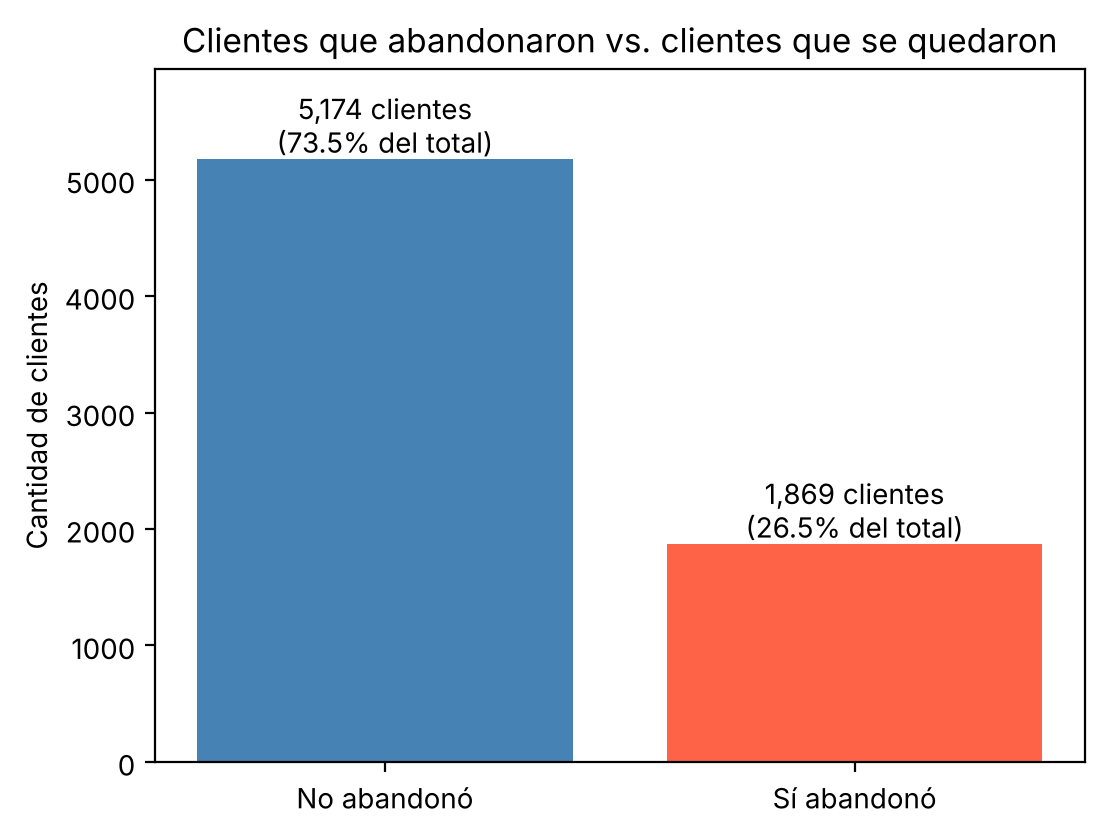

In [12]:
plt.figure(figsize=(6, 4.5))
barras = plt.bar(["No abandonó", "Sí abandonó"], cantidad.values, color=[COLOR_SE_QUEDA, COLOR_ABANDONA])
etiquetas = [f"{c:,} clientes\n({p}% del total)" for c, p in zip(cantidad.values, porcentaje.values)]
plt.bar_label(barras, labels=etiquetas)
plt.ylim(0, cantidad.max() * 1.15)
plt.title("Clientes que abandonaron vs. clientes que se quedaron")
plt.ylabel("Cantidad de clientes")
plt.show()

**Lo que observamos:**

- **1,869 clientes abandonaron (26.5%)** y 5,174 se quedaron (73.5%).
- Es decir, aproximadamente **1 de cada 4 clientes se fue**. Para una empresa esto es bastante.
- Los dos grupos no tienen el mismo tamaño: hay casi 3 clientes que se quedan por cada 1 que se va. Esto es importante para la etapa de los modelos, porque un modelo que diga siempre "no abandona" acertaría el 73.5% de las veces sin haber aprendido nada. Por eso el enunciado pide evaluar con *precision*, *recall* y *F1* y no solo con el porcentaje de aciertos.

Para poder calcular porcentajes de abandono más fácil, creamos una columna de apoyo con 1 si abandonó y 0 si no:

In [13]:
df["Abandono"] = (df["Churn"] == "Yes").astype(int)
print("Porcentaje general de abandono:", round(df["Abandono"].mean() * 100, 1), "%")

Porcentaje general de abandono: 26.5 %



### 4.1 ¿Cuántos abandonaron en relación con el total de la muestra? (por tipo de contrato)

La muestra completa tiene **7,043 clientes** y de ellos **1,869 abandonaron**. Para entender mejor de dónde salen esos 1,869, los separamos por tipo de contrato. La tabla muestra, para cada contrato:

- **Abandonaron:** cuántos clientes se fueron.
- **Abandono dentro del contrato (%):** de los clientes de ese contrato, qué porcentaje se fue.
- **% del total de abandonos:** de los 1,869 que se fueron, qué porcentaje tenía ese contrato (las tres filas suman 100%).
- **% de la muestra total:** cuántos son los que abandonaron de ese contrato comparados con los 7,043 clientes (las tres filas suman 26.5%).


In [14]:

total_clientes = len(df)
total_abandonos = df["Abandono"].sum()

tabla_contrato = df.groupby("Contract")["Abandono"].agg(["count", "sum"])
tabla_contrato.columns = ["Cantidad de clientes", "Abandonaron"]
tabla_contrato["Se quedaron"] = tabla_contrato["Cantidad de clientes"] - tabla_contrato["Abandonaron"]
tabla_contrato["Abandono dentro del contrato (%)"] = (tabla_contrato["Abandonaron"] / tabla_contrato["Cantidad de clientes"] * 100).round(1)
tabla_contrato["% del total de abandonos"] = (tabla_contrato["Abandonaron"] / total_abandonos * 100).round(1)
tabla_contrato["% de la muestra total"] = (tabla_contrato["Abandonaron"] / total_clientes * 100).round(1)

print("TOTAL:", f"{total_abandonos:,}", "de", f"{total_clientes:,}", "clientes abandonaron",
      "(" + str(round(total_abandonos / total_clientes * 100, 1)) + "% de la muestra)\n")
tabla_contrato


TOTAL: 1,869 de 7,043 clientes abandonaron (26.5% de la muestra)



,Cantidad de clientes,Abandonaron,Se quedaron,Abandono dentro del contrato (%),% del total de abandonos,% de la muestra total
Contract,,,,,,
Month-to-month,3875,1655,2220,42.7,88.6,23.5
One year,1473,166,1307,11.3,8.9,2.4
Two year,1695,48,1647,2.8,2.6,0.7


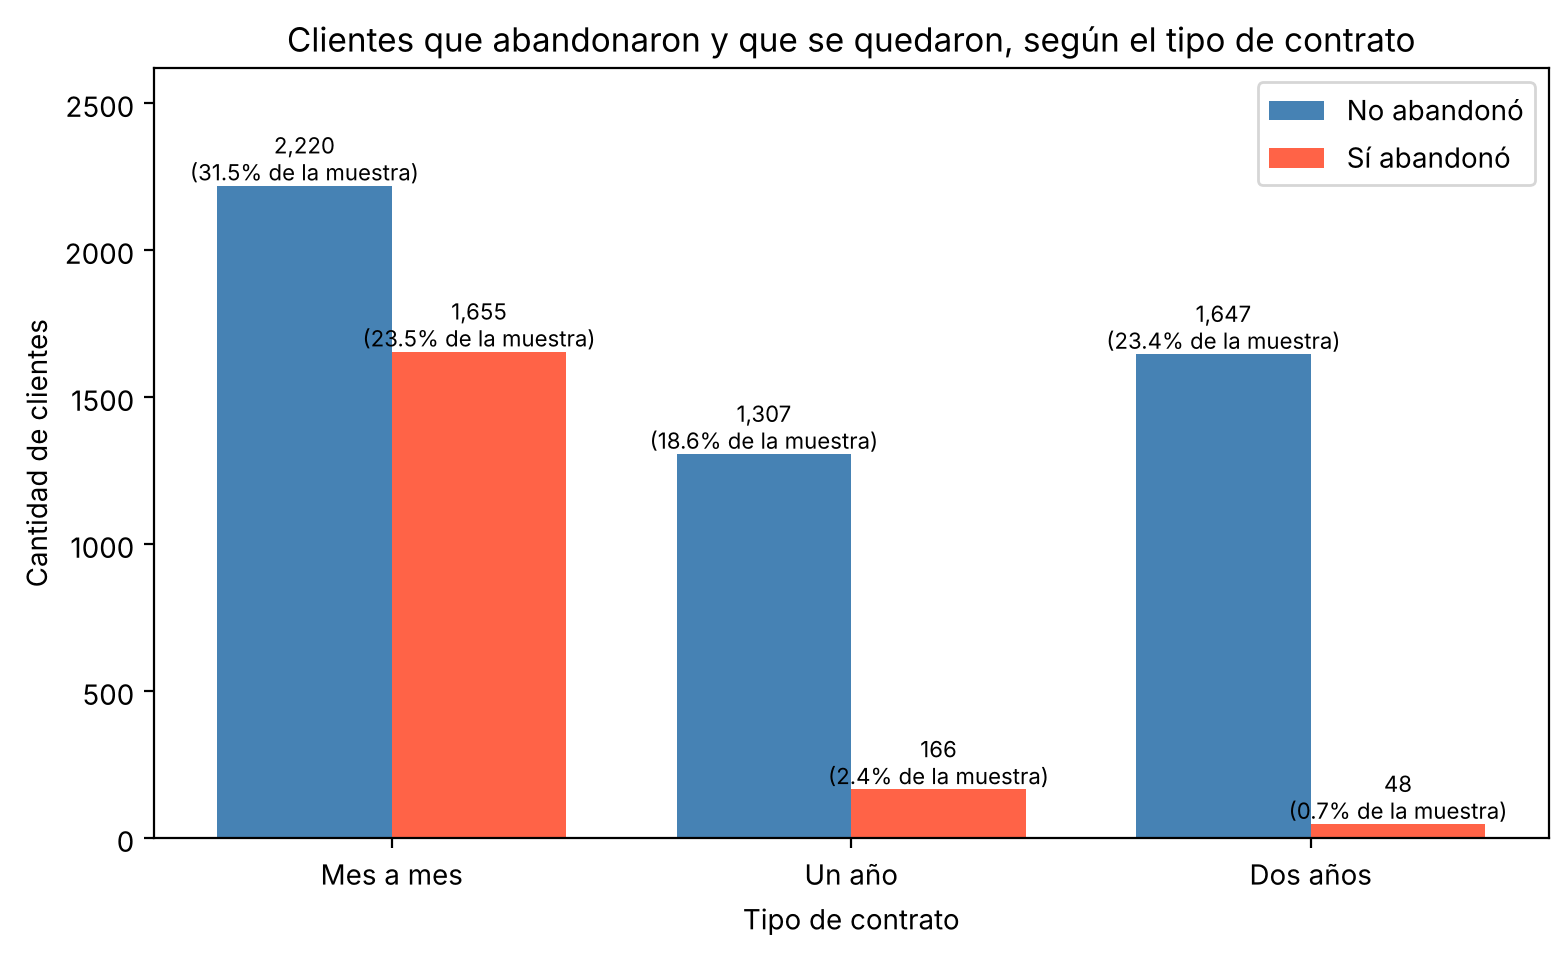

In [15]:

nombres_contrato = {"Month-to-month": "Mes a mes", "One year": "Un año", "Two year": "Dos años"}
posiciones = np.arange(len(tabla_contrato))
ancho = 0.38

plt.figure(figsize=(9, 5))
b1 = plt.bar(posiciones - ancho / 2, tabla_contrato["Se quedaron"], ancho, color=COLOR_SE_QUEDA, label="No abandonó")
b2 = plt.bar(posiciones + ancho / 2, tabla_contrato["Abandonaron"], ancho, color=COLOR_ABANDONA, label="Sí abandonó")

plt.bar_label(b1, labels=[f"{n:,}\n({n / total_clientes * 100:.1f}% de la muestra)" for n in tabla_contrato["Se quedaron"]], fontsize=8)
plt.bar_label(b2, labels=[f"{n:,}\n({n / total_clientes * 100:.1f}% de la muestra)" for n in tabla_contrato["Abandonaron"]], fontsize=8)

plt.xticks(posiciones, [nombres_contrato[c] for c in tabla_contrato.index])
plt.ylim(0, tabla_contrato["Se quedaron"].max() * 1.18)
plt.title("Clientes que abandonaron y que se quedaron, según el tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Cantidad de clientes")
plt.legend()
plt.show()



**Lo que observamos:**

- De los **7,043 clientes**, **1,869 abandonaron (26.5%)**.
- **1,655 de esos 1,869 tenían contrato mes a mes**. O sea, **casi 9 de cada 10 abandonos (88.6%)** vienen de ese contrato, y por sí solo representa el **23.5% de toda la muestra**.
- Los de contrato de un año aportan 166 abandonos (8.9% de los abandonos, 2.4% de la muestra) y los de dos años solo 48 (2.6% de los abandonos, 0.7% de la muestra).
- Esto no es solo porque el contrato mes a mes tenga más clientes (3,875): dentro de cada contrato, el abandono es de **42.7%** en mes a mes, **11.3%** en un año y **2.8%** en dos años.


## 5. Analizamos las columnas con números

Las columnas con números son tres: la antigüedad (`tenure`), el cargo mensual (`MonthlyCharges`) y el cargo total (`TotalCharges`).

### 5.1 Resumen de las tres columnas

In [16]:
columnas_numeros = ["tenure", "MonthlyCharges", "TotalCharges"]
df[columnas_numeros].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.80
std,24.56,30.09,2266.73
min,0.00,18.25,18.80
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


**Lo que observamos:**

- **Antigüedad (`tenure`):** va de 0 a 72 meses (6 años). En promedio los clientes llevan unos 32 meses.
- **Cargo mensual (`MonthlyCharges`):** va de 18.25 a 118.75. El promedio es de unos 64.76 al mes.
- **Cargo total (`TotalCharges`):** va de 18.80 a 8,684.80. Aquí hay mucha diferencia entre clientes, lo cual es normal porque depende de cuánto tiempo llevan en la empresa.
- No vemos valores imposibles (por ejemplo cargos negativos o antigüedades exageradas).

### 5.2 ¿Cómo se reparten los valores?

Con los histogramas vemos dónde se concentran los clientes.

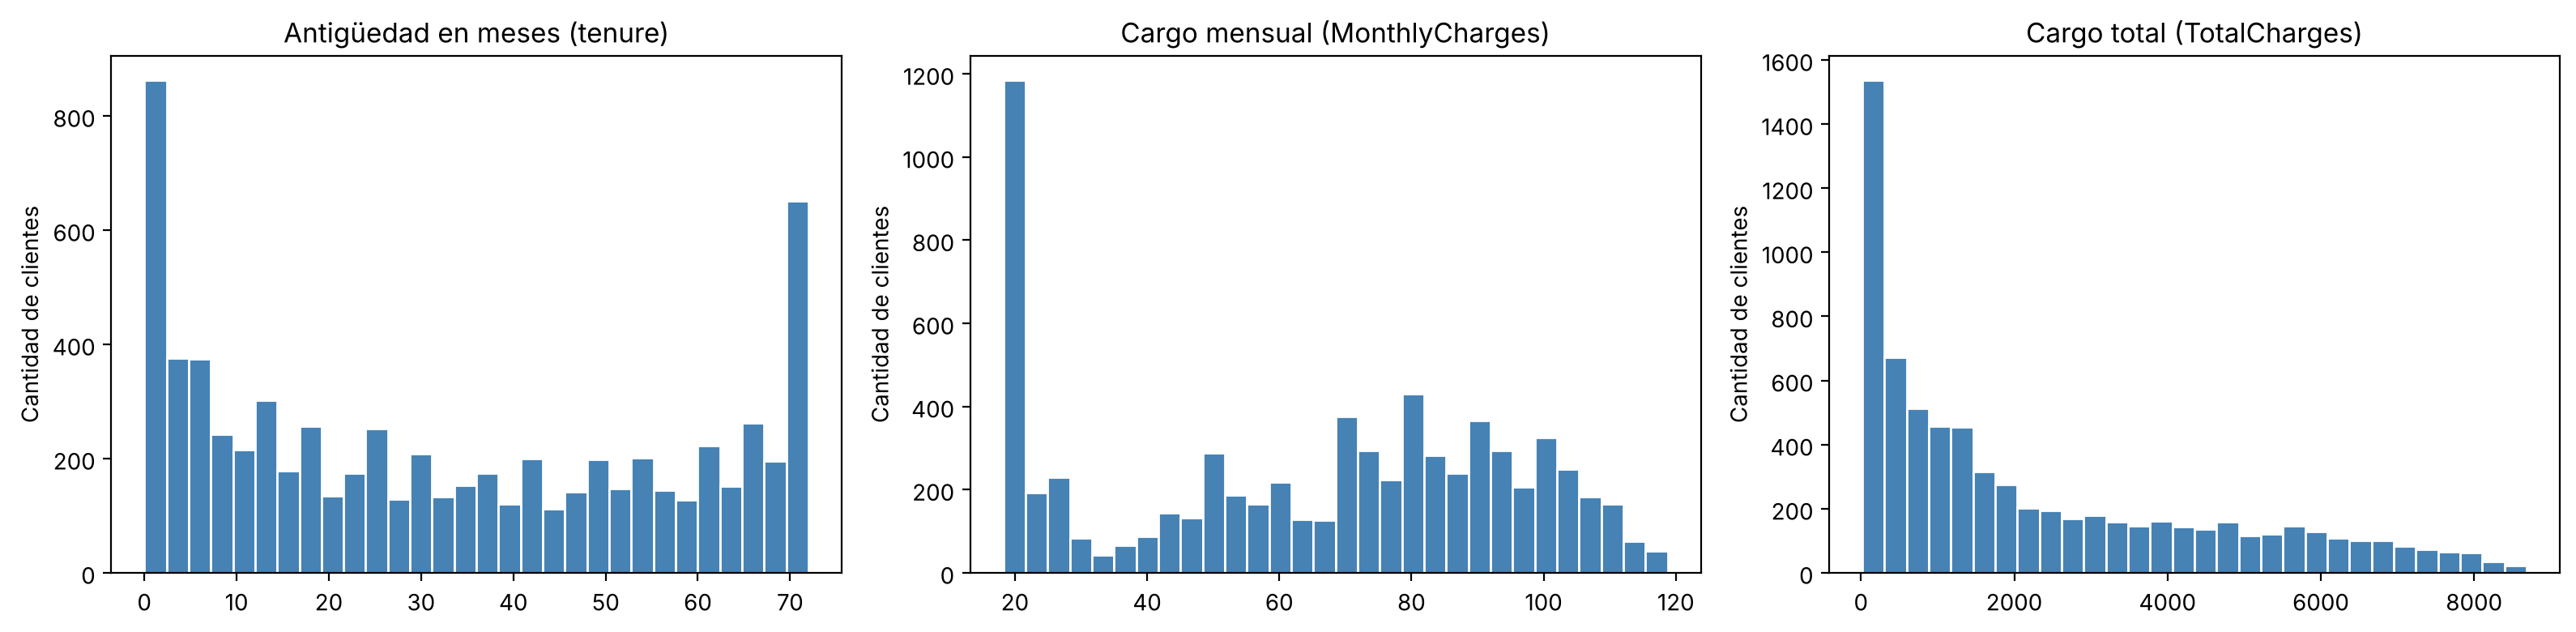

In [17]:
titulos = ["Antigüedad en meses (tenure)", "Cargo mensual (MonthlyCharges)", "Cargo total (TotalCharges)"]

plt.figure(figsize=(16, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.hist(df[columnas_numeros[i]], bins=30, color=COLOR_SE_QUEDA, edgecolor="white")
    plt.title(titulos[i])
    plt.ylabel("Cantidad de clientes")
plt.tight_layout()
plt.show()

**Lo que observamos:**

- **Antigüedad:** hay dos grupos grandes: muchos clientes muy nuevos (pocos meses) y muchos clientes muy antiguos (cerca de 72 meses).
- **Cargo mensual:** hay un grupo grande que paga muy poco (alrededor de 20, que son los que tienen el servicio más básico) y otro grupo repartido entre 70 y 100.
- **Cargo total:** la mayoría de los clientes tiene totales bajos y pocos tienen totales muy altos. Tiene sentido porque para acumular un total alto hay que llevar mucho tiempo.

### 5.3 ¿Hay diferencia entre los que abandonan y los que se quedan?

Primero comparamos el promedio y la mediana (el valor del medio) de cada columna para los dos grupos. Debajo hacemos un gráfico de barras con el **promedio** de cada grupo, que es más fácil de leer.

In [18]:
df.groupby("Churn")[columnas_numeros].agg(["mean", "median"]).round(2)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43       2550.0  1679.52
Yes    17.98   10.0          74.44  79.65       1531.8   703.55

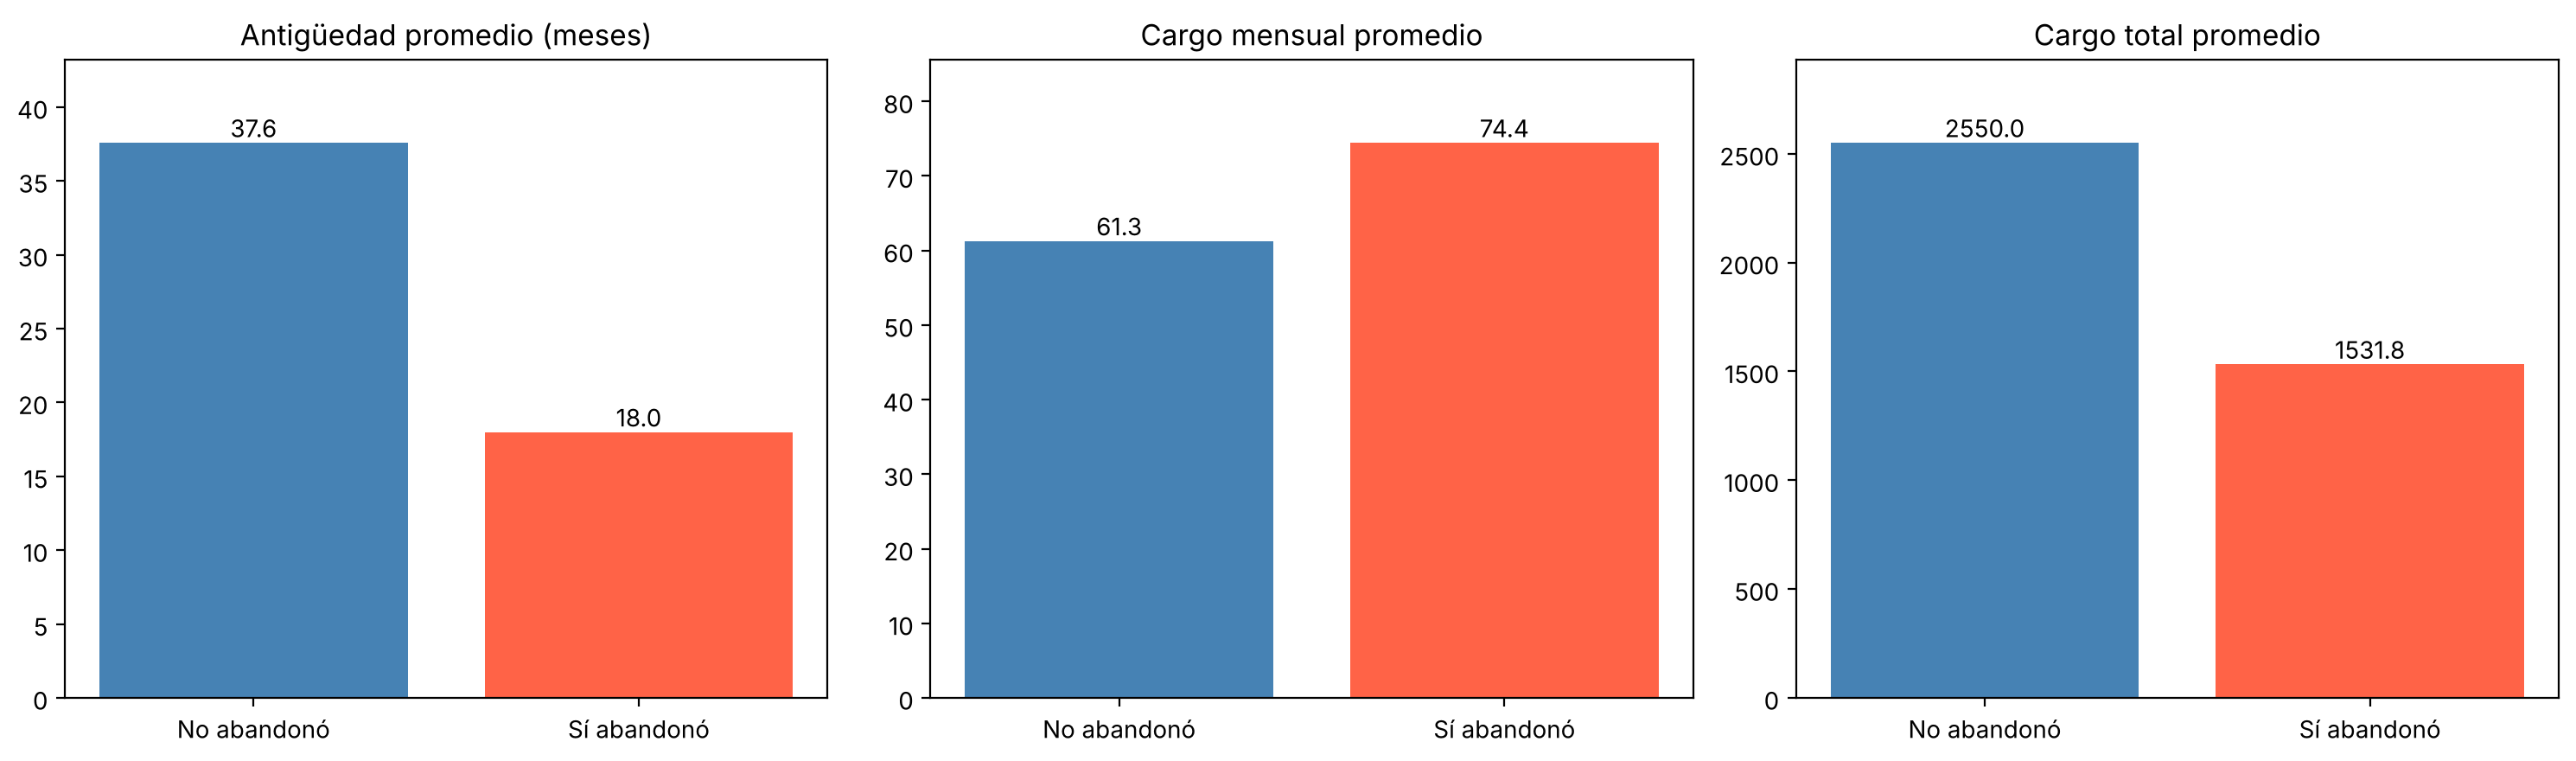

In [19]:
promedios = df.groupby("Churn")[columnas_numeros].mean().round(2)
titulos_promedio = ["Antigüedad promedio (meses)", "Cargo mensual promedio", "Cargo total promedio"]

plt.figure(figsize=(15, 4.5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    valores = [promedios.loc["No", columnas_numeros[i]], promedios.loc["Yes", columnas_numeros[i]]]
    barras = plt.bar(["No abandonó", "Sí abandonó"], valores, color=[COLOR_SE_QUEDA, COLOR_ABANDONA])
    plt.bar_label(barras, fmt="%.1f")
    plt.ylim(0, max(valores) * 1.15)
    plt.title(titulos_promedio[i])
plt.tight_layout()
plt.show()

**Lo que observamos:**

- **Antigüedad:** aquí está la diferencia más grande. Los que abandonaron llevaban en promedio **18 meses**, mientras que los que se quedaron llevan casi **38 meses**. La mitad de los que se fueron lo hizo antes de los **10 meses**.
- **Cargo mensual:** los que abandonaron pagaban **más al mes** (promedio 74.44) que los que se quedaron (promedio 61.27).
- **Cargo total:** los que abandonaron tienen un total **menor** (promedio 1,531.80 contra 2,550.00 de los que se quedaron). Esto parece contradecir lo anterior, pero no: tienen un total menor porque **duraron poco tiempo** en la empresa.

En resumen: **el cliente que se va suele ser nuevo y paga una mensualidad alta.**

### 5.4 Abandono según la antigüedad, por grupos

Para verlo más claro, separamos a los clientes en 4 grupos según el tiempo que llevan.

In [20]:
df["GrupoAntiguedad"] = pd.cut(df["tenure"],
                               bins=[-1, 12, 24, 48, 72],
                               labels=["0 a 12 meses", "13 a 24 meses", "25 a 48 meses", "49 a 72 meses"])

total_abandonos = df["Abandono"].sum()

tabla_antiguedad = df.groupby("GrupoAntiguedad", observed=True)["Abandono"].agg(["count", "sum", "mean"])
tabla_antiguedad.columns = ["Cantidad de clientes", "Abandonaron", "Abandono dentro del grupo (%)"]
tabla_antiguedad["Abandono dentro del grupo (%)"] = (tabla_antiguedad["Abandono dentro del grupo (%)"] * 100).round(1)
tabla_antiguedad["% del total de abandonos"] = (tabla_antiguedad["Abandonaron"] / total_abandonos * 100).round(1)

print("Suma de la columna '% del total de abandonos':", tabla_antiguedad["% del total de abandonos"].sum().round(1), "%")
tabla_antiguedad

Suma de la columna '% del total de abandonos': 100.0 %


,Cantidad de clientes,Abandonaron,Abandono dentro del grupo (%),% del total de abandonos
GrupoAntiguedad,,,,
0 a 12 meses,2186,1037,47.4,55.5
13 a 24 meses,1024,294,28.7,15.7
25 a 48 meses,1594,325,20.4,17.4
49 a 72 meses,2239,213,9.5,11.4


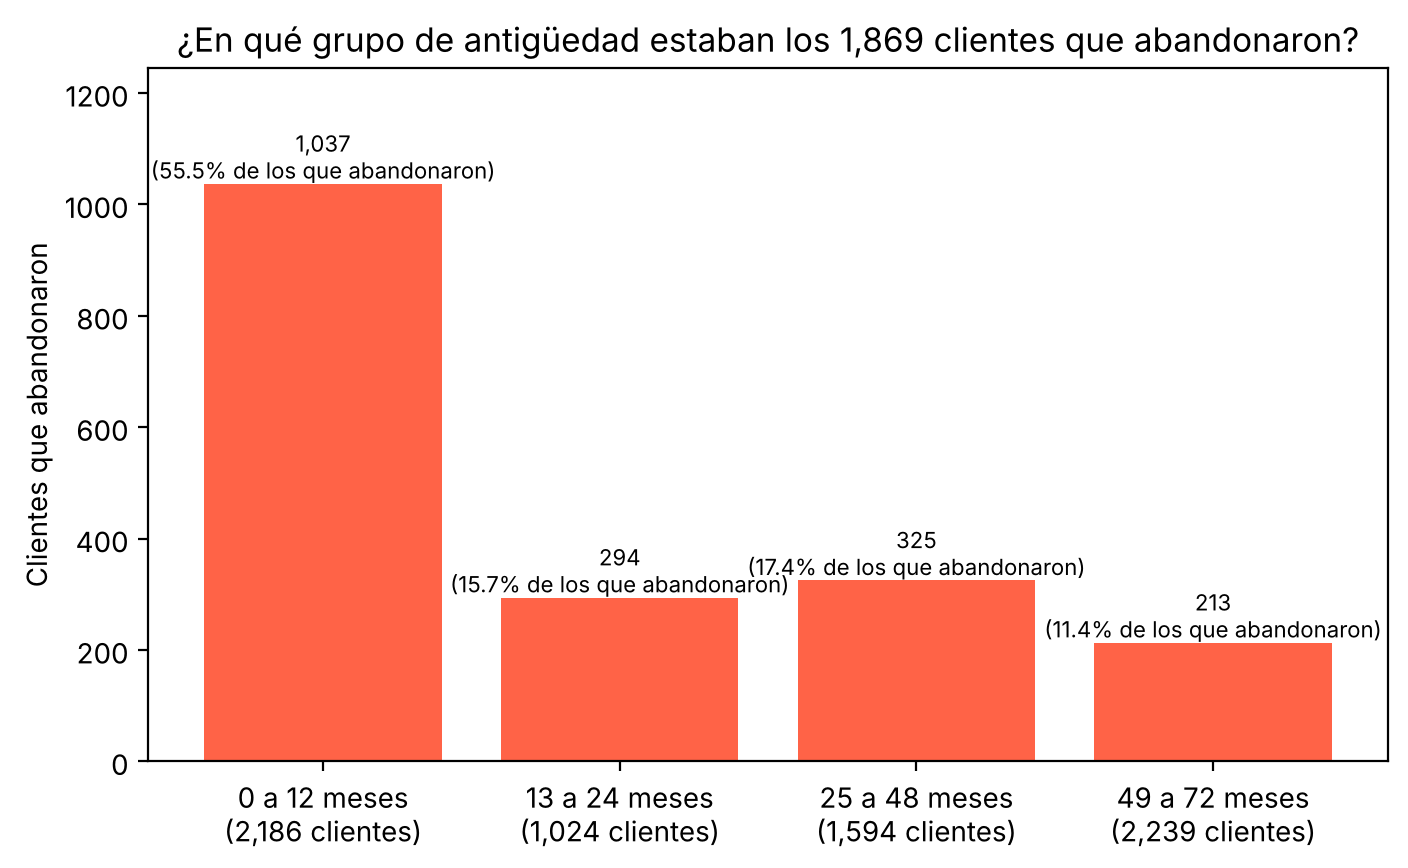

In [21]:
plt.figure(figsize=(8, 4.5))
barras = plt.bar(tabla_antiguedad.index.astype(str), tabla_antiguedad["Abandonaron"], color=COLOR_ABANDONA)
etiquetas = [f"{n:,}\n({p:.1f}% de los que abandonaron)"
             for n, p in zip(tabla_antiguedad["Abandonaron"], tabla_antiguedad["% del total de abandonos"])]
plt.bar_label(barras, labels=etiquetas, fontsize=8)
plt.xticks(range(4), [f"{g}\n({n:,} clientes)" for g, n in zip(tabla_antiguedad.index, tabla_antiguedad["Cantidad de clientes"])])
plt.ylim(0, tabla_antiguedad["Abandonaron"].max() * 1.2)
plt.title(f"¿En qué grupo de antigüedad estaban los {total_abandonos:,} clientes que abandonaron?")
plt.ylabel("Clientes que abandonaron")
plt.show()

**Lo que observamos:**

- De los **1,869 clientes que abandonaron**, **1,037 (55.5%) estaban en su primer año**. Los demás se reparten así: 294 (15.7%) en el segundo año, 325 (17.4%) entre los 25 y 48 meses y 213 (11.4%) después de los 4 años. Los cuatro porcentajes del gráfico **suman 100%**, porque todos se calculan sobre los mismos 1,869 clientes.
- La columna **"Abandono dentro del grupo (%)"** de la tabla es otra cosa: es el porcentaje de abandono dentro de cada grupo (47.4%, 28.7%, 20.4% y 9.5%). Esos porcentajes **no suman 100%** y está bien, porque cada uno se calcula sobre un grupo de clientes distinto.
- Mientras más tiempo lleva el cliente, menos abandona: casi la mitad de los clientes del primer año se fue (**47.4%**), contra solo el **9.5%** de los que llevan más de 4 años.

Esto nos dice que **el primer año es el momento más delicado** y donde la empresa debería poner más atención.

### 5.5 Relación entre las columnas con números

La correlación es un número entre -1 y 1 que indica qué tanto se mueven juntas dos columnas:

- Cerca de **1**: cuando una sube, la otra también sube.
- Cerca de **-1**: cuando una sube, la otra baja.
- Cerca de **0**: no tienen relación.

In [22]:
correlacion = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Abandono"]].corr().round(2)
correlacion

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Abandono
tenure,1.00,0.25,0.83,0.02,-0.35
MonthlyCharges,0.25,1.00,0.65,0.22,0.19
TotalCharges,0.83,0.65,1.00,0.10,-0.20
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
Abandono,-0.35,0.19,-0.20,0.15,1.00


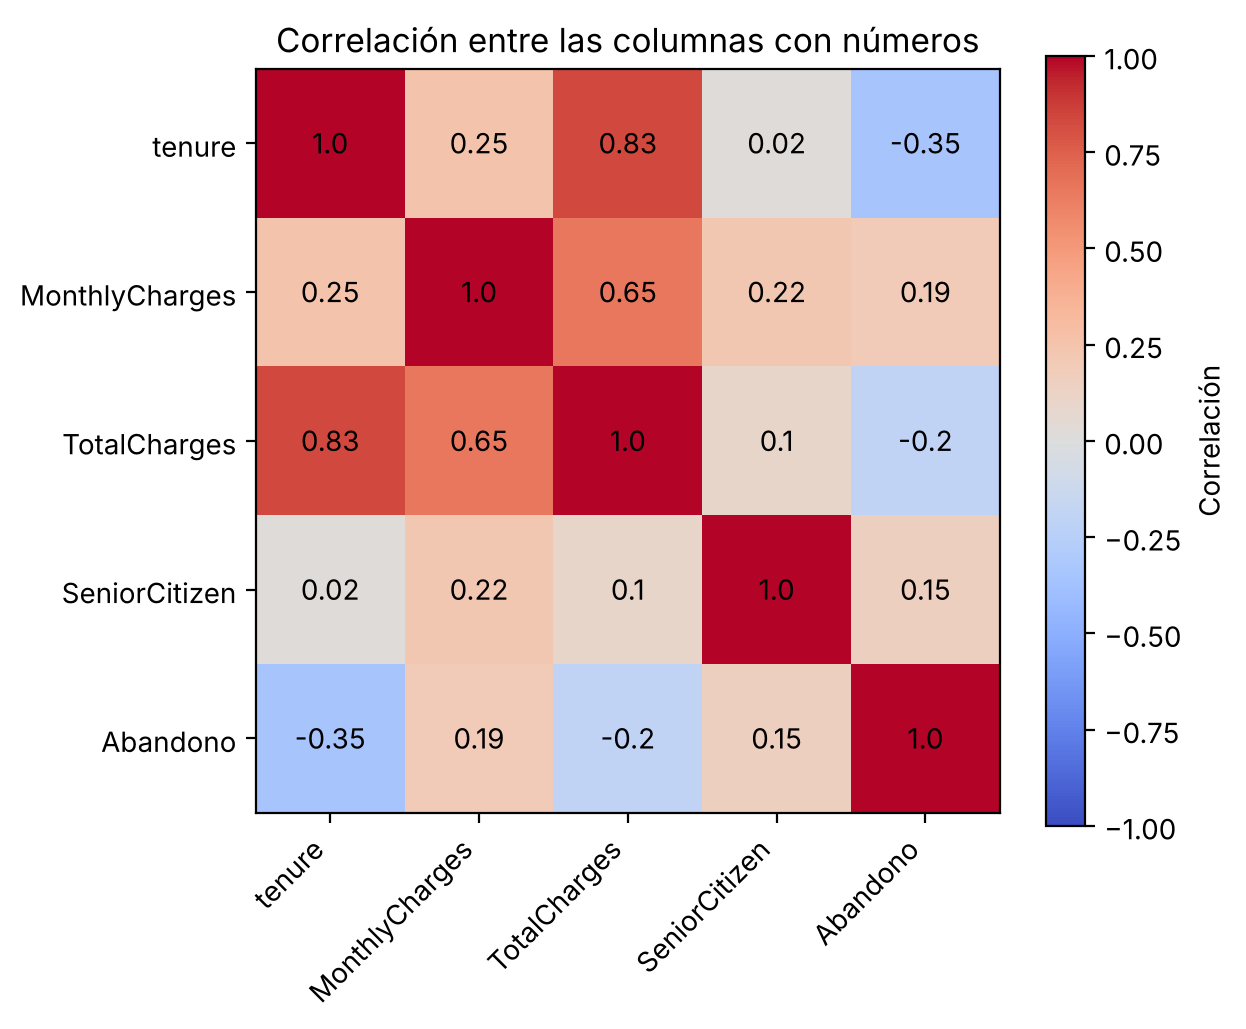

In [23]:
plt.figure(figsize=(6, 5))
plt.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlación")
plt.xticks(range(5), correlacion.columns, rotation=45, ha="right")
plt.yticks(range(5), correlacion.columns)

# Escribimos el número dentro de cada cuadro
for fila in range(5):
    for columna in range(5):
        plt.text(columna, fila, correlacion.iloc[fila, columna], ha="center", va="center")

plt.title("Correlación entre las columnas con números")
plt.show()

**Lo que observamos:**

- `tenure` y `TotalCharges` tienen una relación muy fuerte (**0.83**). Es lógico: mientras más tiempo lleva un cliente, más ha pagado en total. De hecho, el cargo total es más o menos el cargo mensual multiplicado por los meses. **Esto quiere decir que `TotalCharges` repite información que ya dan las otras dos columnas**, y se lo dejamos como aviso al equipo de modelado.
- La antigüedad tiene relación **negativa** con el abandono (**-0.35**): a más tiempo, menos abandono.
- El cargo mensual tiene relación **positiva** con el abandono (**0.19**): a mayor mensualidad, un poco más de abandono.

## 6. Analizamos las columnas con categorías

Para no repetir el mismo código muchas veces, hicimos una función. La función recibe el nombre de una columna y nos devuelve una tabla con, para cada categoría:

- **Cantidad de clientes:** cuántos clientes hay en esa categoría.
- **Abandonaron:** cuántos de ellos se fueron.
- **Abandono (%):** el porcentaje de abandono **dentro de esa categoría** (Abandonaron ÷ Cantidad de clientes).
- **% del total de abandonos:** qué parte de los 1,869 abandonos corresponde a esa categoría.
- **% de la muestra total:** los que abandonaron en esa categoría comparados con los 7,043 clientes de toda la muestra.

También hicimos otra función que dibuja el gráfico.

In [24]:
def tabla_abandono(columna):
    tabla = df.groupby(columna)["Abandono"].agg(["count", "sum", "mean"])
    tabla.columns = ["Cantidad de clientes", "Abandonaron", "Abandono (%)"]
    tabla["Abandono (%)"] = (tabla["Abandono (%)"] * 100).round(1)
    tabla["% del total de abandonos"] = (tabla["Abandonaron"] / df["Abandono"].sum() * 100).round(1)
    tabla["% de la muestra total"] = (tabla["Abandonaron"] / len(df) * 100).round(1)
    return tabla.sort_values("Abandono (%)", ascending=False)


def grafico_abandono(columnas, titulos):
    promedio_general = df["Abandono"].mean() * 100
    plt.figure(figsize=(6 * len(columnas), 4.5))
    for i in range(len(columnas)):
        tabla = tabla_abandono(columnas[i])
        plt.subplot(1, len(columnas), i + 1)
        barras = plt.bar(tabla.index.astype(str), tabla["Abandono (%)"], color=COLOR_ABANDONA)
        # Arriba de cada barra: el porcentaje y, entre paréntesis, cuántos abandonaron de cuántos clientes hay
        etiquetas = [f"{p:.1f}%\n({n:,} de {t:,})"
                     for p, n, t in zip(tabla["Abandono (%)"], tabla["Abandonaron"], tabla["Cantidad de clientes"])]
        plt.bar_label(barras, labels=etiquetas, fontsize=8)
        plt.axhline(promedio_general, color="gray", linestyle="--")
        plt.title(titulos[i])
        plt.ylabel("Abandono (%)")
        plt.ylim(0, 65)
        plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

En todos los gráficos que siguen, **la línea gris punteada es el promedio general de abandono (26.5%)**. Si una barra queda por encima de la línea, esa categoría abandona más de lo normal. Arriba de cada barra se ve el porcentaje y, entre paréntesis, **cuántos clientes abandonaron del total de clientes de esa categoría** (por ejemplo, "1,655 de 3,875").

### 6.1 Datos personales del cliente

In [25]:
for columna in ["gender", "AdultoMayor", "Partner", "Dependents"]:
    print(tabla_abandono(columna), "\n")

        Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
gender                                                                                                  
Female                  3488          939          26.9                      50.2                   13.3
Male                    3555          930          26.2                      49.8                   13.2 

             Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
AdultoMayor                                                                                                  
Sí                           1142          476          41.7                      25.5                    6.8
No                           5901         1393          23.6                      74.5                   19.8 

         Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
Partner                       

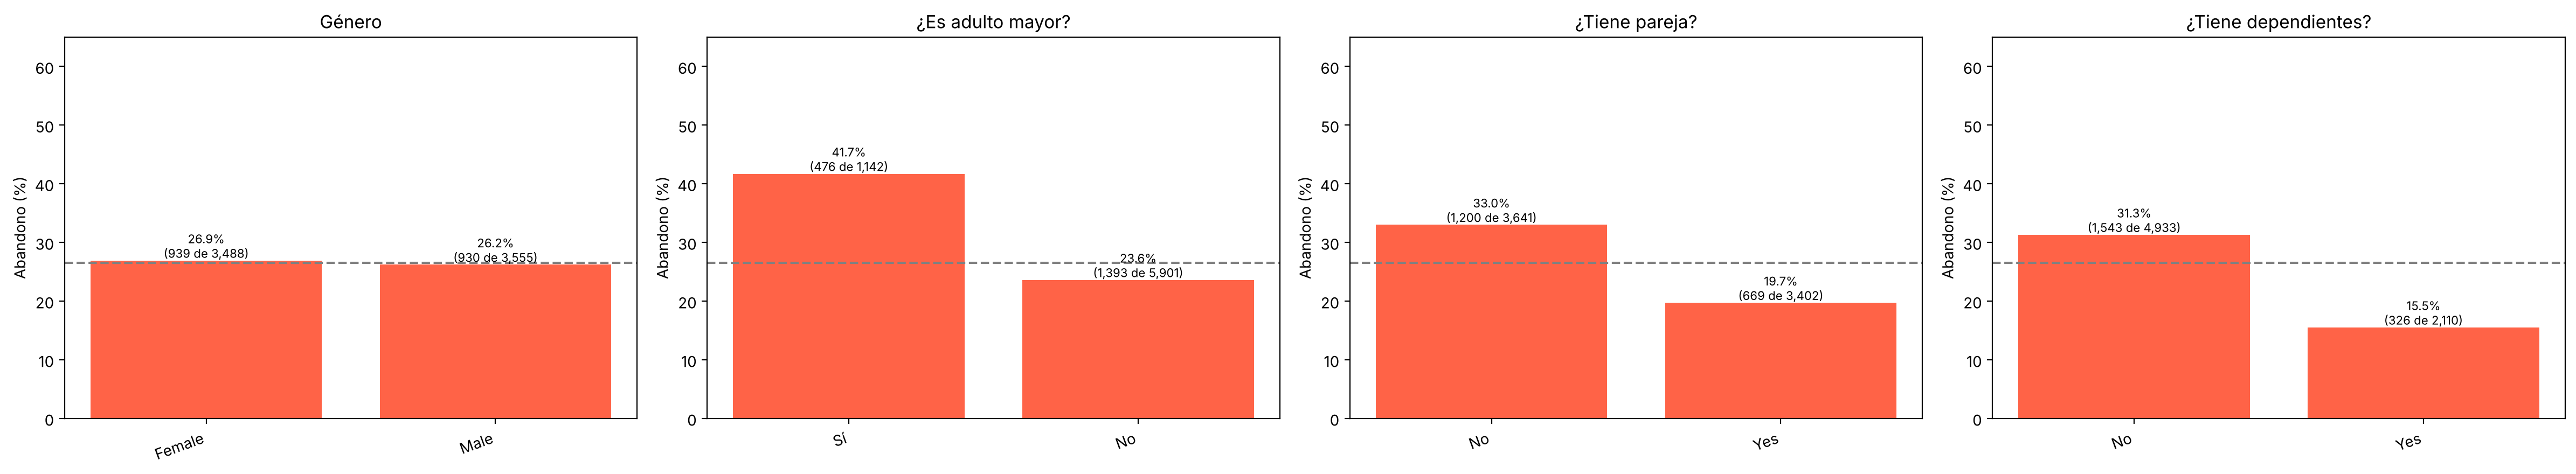

In [26]:
grafico_abandono(["gender", "AdultoMayor", "Partner", "Dependents"],
                 ["Género", "¿Es adulto mayor?", "¿Tiene pareja?", "¿Tiene dependientes?"])

**Lo que observamos:**

- **Género:** prácticamente no hay diferencia (26.9% mujeres y 26.2% hombres). **El género no parece influir en el abandono.**
- **Adulto mayor:** los adultos mayores abandonan bastante más (**41.7%**) que el resto (23.6%). Eso sí, son un grupo pequeño: 1,142 clientes.
- **Pareja:** los que **no** tienen pareja abandonan más (33.0%) que los que sí tienen (19.7%).
- **Dependientes:** los que **no** tienen dependientes abandonan el doble (31.3%) que los que sí tienen (15.5%).

Parece que los clientes con familia son más estables.

### 6.2 Contrato y forma de pago

In [27]:
for columna in ["Contract", "PaperlessBilling", "PaymentMethod"]:
    print(tabla_abandono(columna), "\n")

                Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
Contract                                                                                                        
Month-to-month                  3875         1655          42.7                      88.6                   23.5
One year                        1473          166          11.3                       8.9                    2.4
Two year                        1695           48           2.8                       2.6                    0.7 

                  Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
PaperlessBilling                                                                                                  
Yes                               4171         1400          33.6                      74.9                   19.9
No                                2872          469          16.3                      2

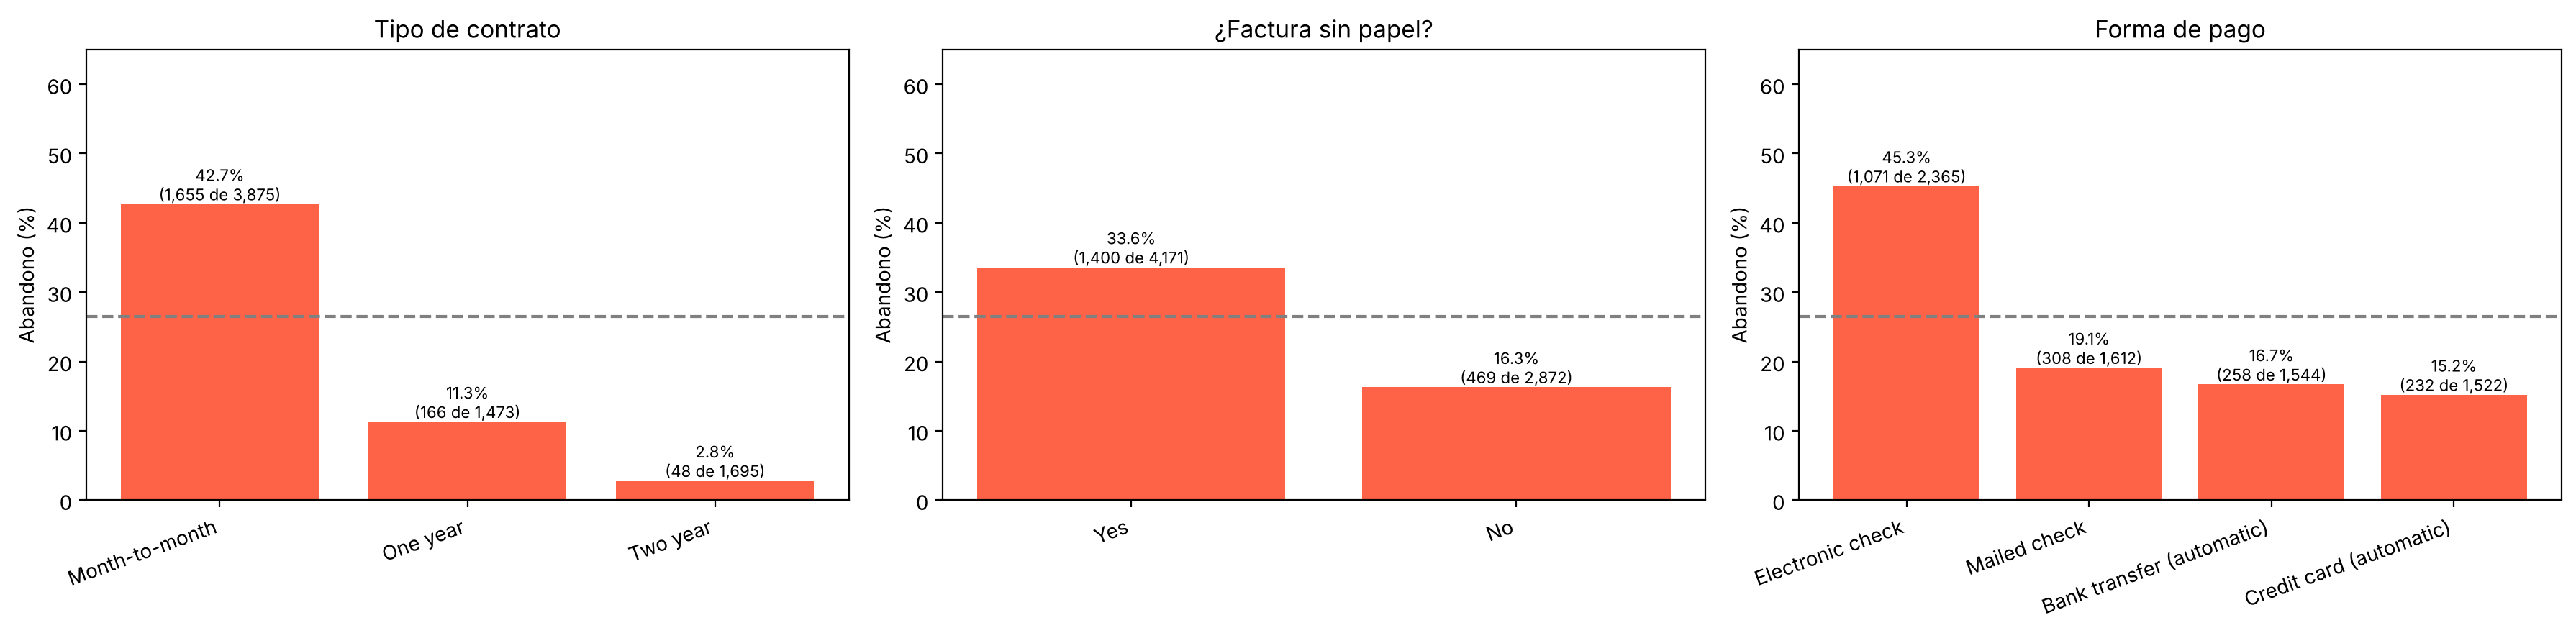

In [28]:
grafico_abandono(["Contract", "PaperlessBilling", "PaymentMethod"],
                 ["Tipo de contrato", "¿Factura sin papel?", "Forma de pago"])

**Lo que observamos:**

- **Tipo de contrato:** esta es la diferencia más fuerte que encontramos en todo el análisis. Los clientes con contrato **mes a mes abandonan el 42.7%** (1,655 de 3,875), los de un año el 11.3% (166 de 1,473) y los de dos años apenas el **2.8%** (48 de 1,695). El contrato mes a mes es el más común (más de la mitad de la muestra) y concentra el **88.6% de todos los abandonos**.
- **Factura sin papel:** los que la tienen abandonan más (33.6%) que los que no (16.3%).
- **Forma de pago:** los que pagan con **cheque electrónico** (*Electronic check*) abandonan mucho más (**45.3%**) que los demás, que están entre 15% y 19%. Los pagos automáticos (tarjeta o transferencia) son los que menos abandonan.

### 6.3 Servicios de teléfono e internet

In [29]:
for columna in ["PhoneService", "MultipleLines", "InternetService"]:
    print(tabla_abandono(columna), "\n")

              Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
PhoneService                                                                                                  
Yes                           6361         1699          26.7                      90.9                   24.1
No                             682          170          24.9                       9.1                    2.4 

                  Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
MultipleLines                                                                                                     
Yes                               2971          850          28.6                      45.5                   12.1
No                                3390          849          25.0                      45.4                   12.1
No phone service                   682          170          24.9                       9.1   

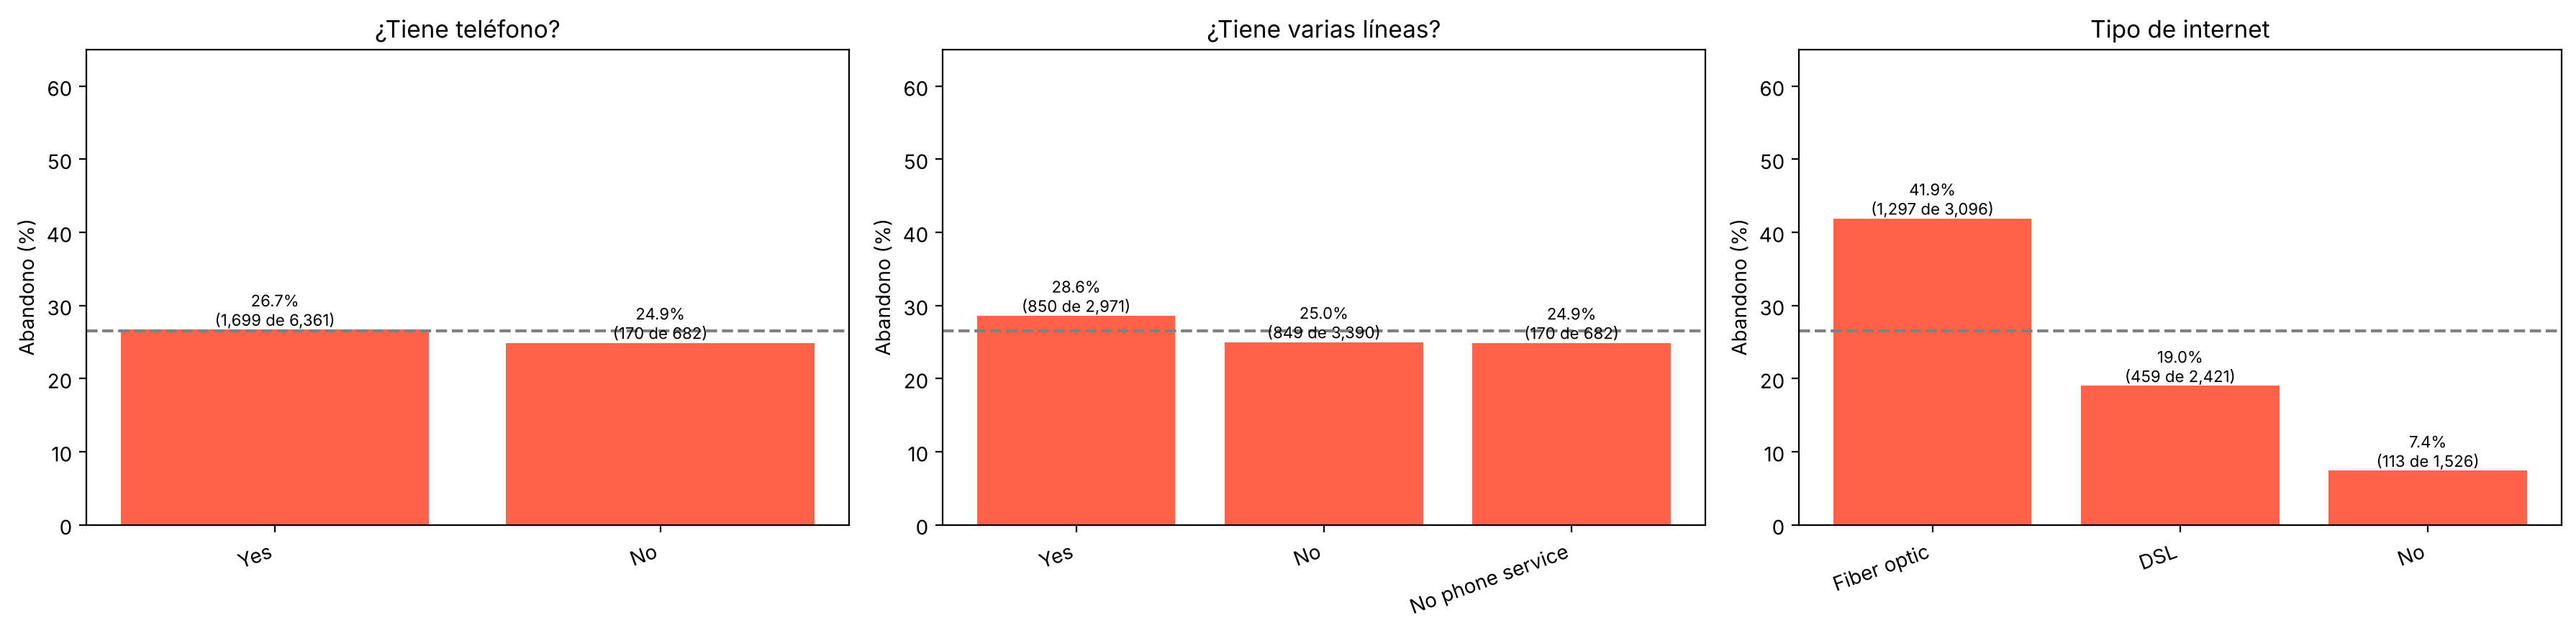

In [30]:
grafico_abandono(["PhoneService", "MultipleLines", "InternetService"],
                 ["¿Tiene teléfono?", "¿Tiene varias líneas?", "Tipo de internet"])

**Lo que observamos:**

- **Teléfono y varias líneas:** hay muy poca diferencia (todos entre 25% y 29%). No parecen ser importantes para el abandono.
- **Tipo de internet:** aquí sí hay una gran diferencia. Los clientes con **fibra óptica abandonan el 41.9%**, los de DSL el 19.0% y los que no tienen internet solo el 7.4%.

Lo de la fibra óptica nos sorprendió, porque es el servicio más moderno. Puede ser que sea más caro o que los clientes no estén satisfechos con el servicio. Con estos datos no podemos saber la razón exacta, solo que existe la relación.

### 6.4 Servicios adicionales de internet

In [31]:
servicios = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]

for columna in servicios:
    print(tabla_abandono(columna), "\n")

                     Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
OnlineSecurity                                                                                                       
No                                   3498         1461          41.8                      78.2                   20.7
Yes                                  2019          295          14.6                      15.8                    4.2
No internet service                  1526          113           7.4                       6.0                    1.6 

                     Cantidad de clientes  Abandonaron  Abandono (%)  % del total de abandonos  % de la muestra total
TechSupport                                                                                                          
No                                   3473         1446          41.6                      77.4                   20.5
Yes                                  2044          310

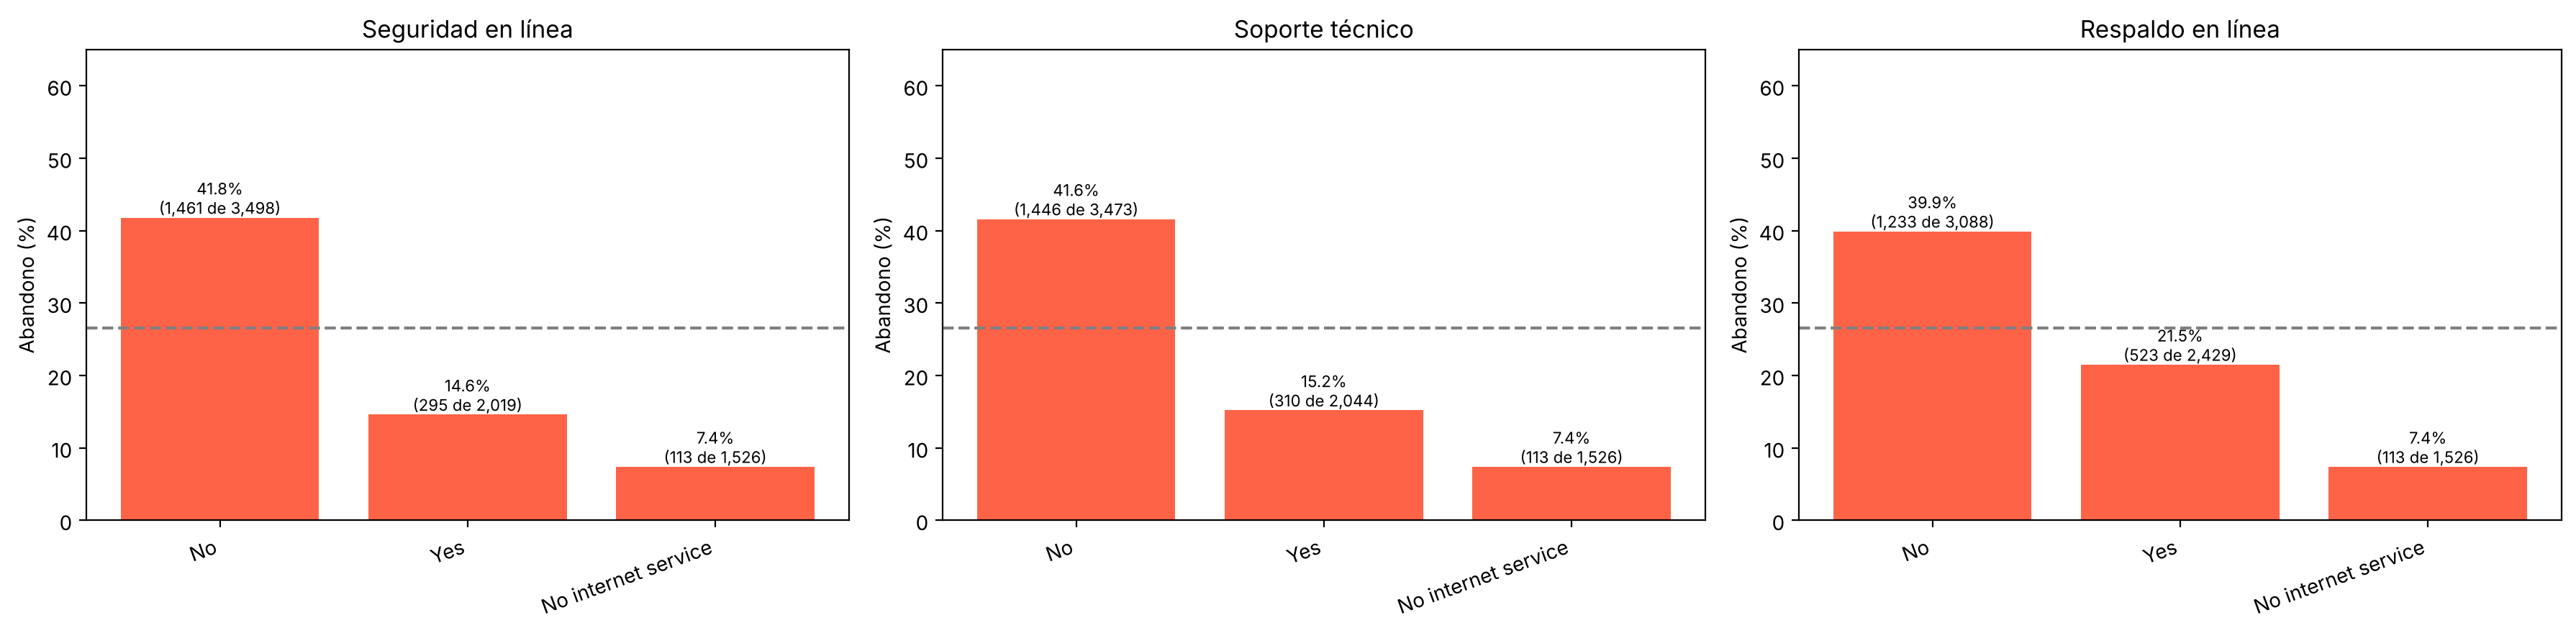

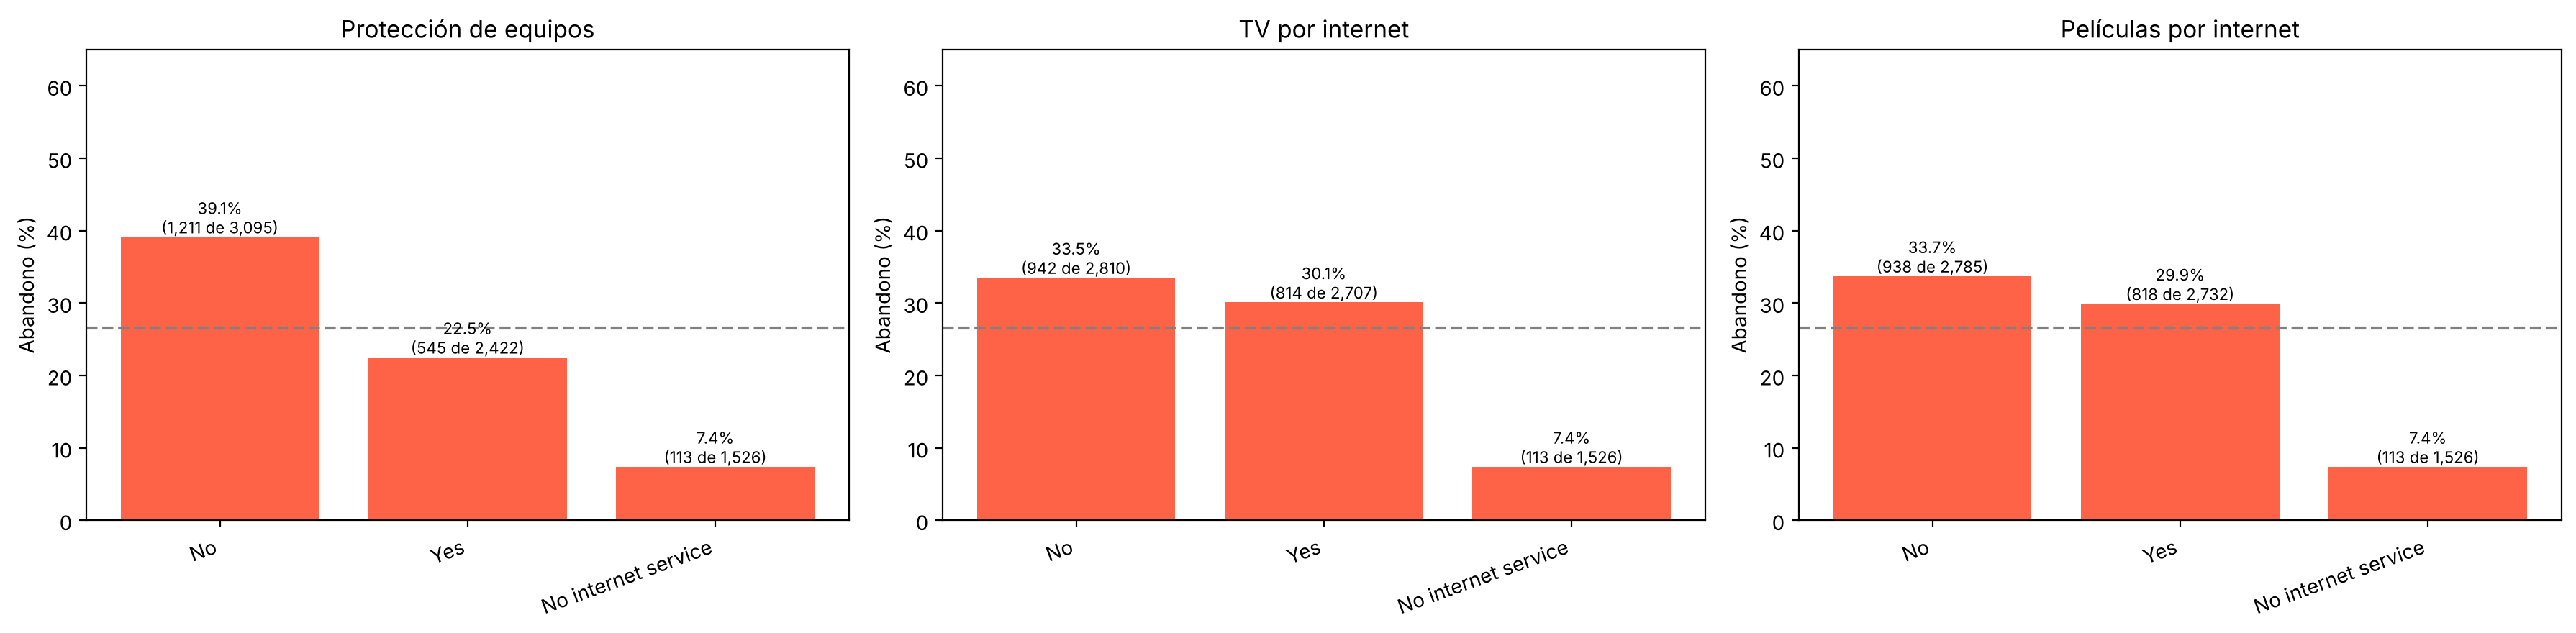

In [32]:
grafico_abandono(["OnlineSecurity", "TechSupport", "OnlineBackup"],
                 ["Seguridad en línea", "Soporte técnico", "Respaldo en línea"])

grafico_abandono(["DeviceProtection", "StreamingTV", "StreamingMovies"],
                 ["Protección de equipos", "TV por internet", "Películas por internet"])

**Lo que observamos:**

- **Seguridad en línea y soporte técnico:** los clientes que tienen internet pero **no** tienen estos servicios abandonan cerca del **42%**. Los que **sí** los tienen abandonan alrededor del 15%. Es una diferencia muy grande.
- **Respaldo en línea y protección de equipos:** pasa lo mismo, pero un poco menos marcado (cerca de 39-40% sin el servicio contra 21-23% con el servicio).
- **TV y películas por internet:** casi no hay diferencia entre tenerlos o no (30% contra 33-34%). No parecen influir mucho.

Los servicios que "protegen" o "ayudan" al cliente parecen hacer que se quede más.

### 6.5 Combinamos las dos variables más fuertes: contrato y tipo de internet

Como el contrato y el tipo de internet fueron las columnas con más diferencia, quisimos ver qué pasa cuando se juntan. La tabla muestra el porcentaje de abandono para cada combinación.

In [33]:
tabla_combinada = pd.pivot_table(df, values="Abandono", index="Contract", columns="InternetService", aggfunc="mean")
tabla_combinada = (tabla_combinada * 100).round(1)
tabla_combinada

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


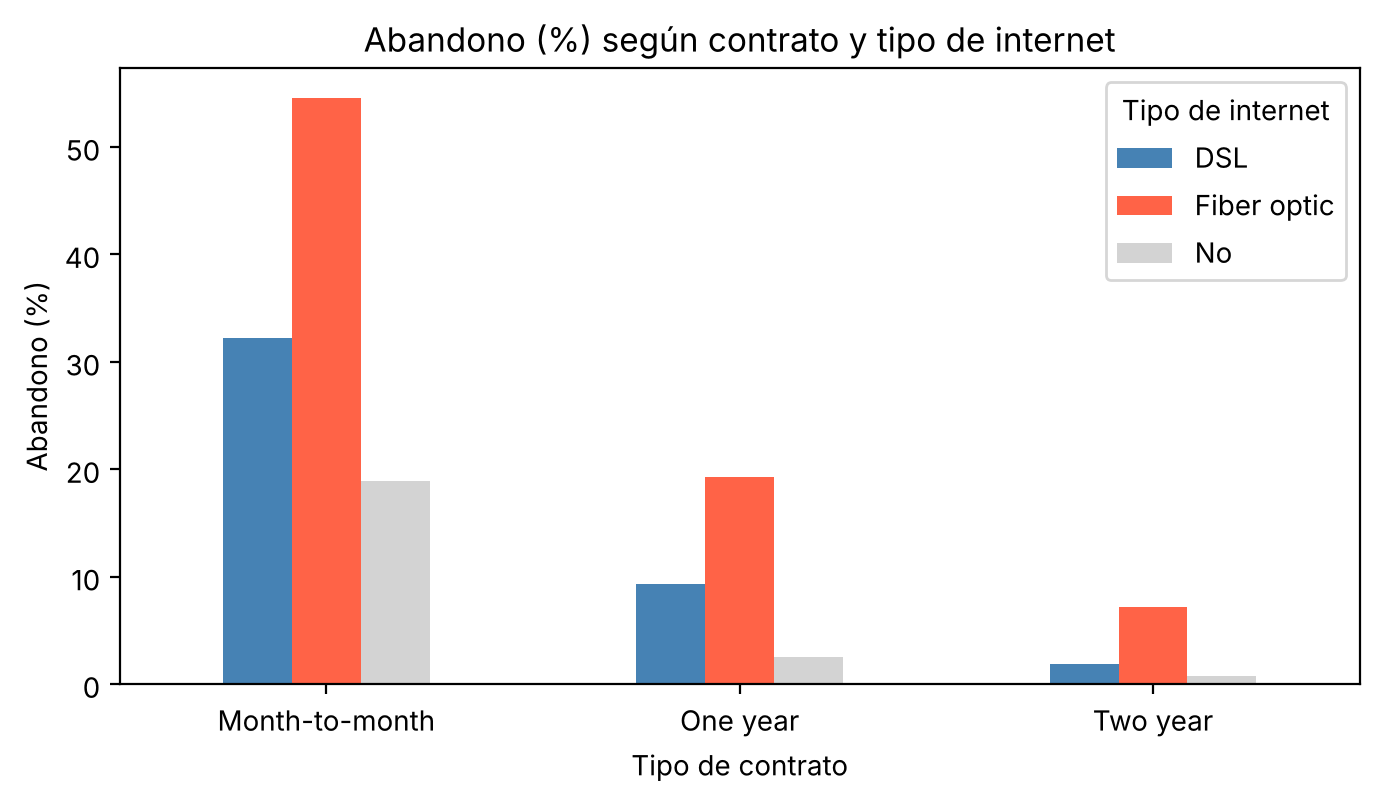

In [34]:
tabla_combinada.plot(kind="bar", figsize=(8, 4), color=["steelblue", "tomato", "lightgray"])
plt.title("Abandono (%) según contrato y tipo de internet")
plt.ylabel("Abandono (%)")
plt.xlabel("Tipo de contrato")
plt.xticks(rotation=0)
plt.legend(title="Tipo de internet")
plt.show()

**Lo que observamos:**

- La combinación con más riesgo es **contrato mes a mes con fibra óptica: abandona el 54.6%**, o sea, más de la mitad.
- Con el mismo internet de fibra óptica, si el contrato es de dos años el abandono baja a 7.2%.
- En todos los tipos de internet se repite lo mismo: mientras más largo es el contrato, menos abandono.
- El grupo más estable es el de contrato de dos años sin internet (0.8%).

Esto nos confirma que **el tipo de contrato es el factor que más pesa**, y que el riesgo sube todavía más cuando se junta con la fibra óptica.

### 6.6 Resumen: ¿qué categorías abandonan más y cuáles menos?

Para cerrar esta parte, juntamos todas las categorías en una sola tabla y las ordenamos de mayor a menor abandono.

In [35]:
columnas_resumen = ["gender", "AdultoMayor", "Partner", "Dependents", "PhoneService", "MultipleLines",
                    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

lista = []
for columna in columnas_resumen:
    tabla = tabla_abandono(columna)
    for categoria in tabla.index:
        lista.append([columna, categoria,
                      tabla.loc[categoria, "Cantidad de clientes"],
                      tabla.loc[categoria, "Abandonaron"],
                      tabla.loc[categoria, "Abandono (%)"],
                      tabla.loc[categoria, "% del total de abandonos"]])

resumen = pd.DataFrame(lista, columns=["Columna", "Categoría", "Cantidad de clientes", "Abandonaron",
                                       "Abandono (%)", "% del total de abandonos"])

print("Las 8 categorías con MÁS porcentaje de abandono:")
resumen.sort_values("Abandono (%)", ascending=False).head(8)

Las 8 categorías con MÁS porcentaje de abandono:


,Columna,Categoría,Cantidad de clientes,Abandonaron,Abandono (%),% del total de abandonos
39,PaymentMethod,Electronic check,2365,1071,45.3,57.3
34,Contract,Month-to-month,3875,1655,42.7,88.6
13,InternetService,Fiber optic,3096,1297,41.9,69.4
16,OnlineSecurity,No,3498,1461,41.8,78.2
2,AdultoMayor,Sí,1142,476,41.7,25.5
25,TechSupport,No,3473,1446,41.6,77.4
19,OnlineBackup,No,3088,1233,39.9,66.0
22,DeviceProtection,No,3095,1211,39.1,64.8


In [36]:
print("Las 8 categorías con MENOS porcentaje de abandono:")
resumen.sort_values("Abandono (%)", ascending=False).tail(8)

Las 8 categorías con MENOS porcentaje de abandono:


,Columna,Categoría,Cantidad de clientes,Abandonaron,Abandono (%),% del total de abandonos
24,DeviceProtection,No internet service,1526,113,7.4,6.0
21,OnlineBackup,No internet service,1526,113,7.4,6.0
15,InternetService,No,1526,113,7.4,6.0
18,OnlineSecurity,No internet service,1526,113,7.4,6.0
33,StreamingMovies,No internet service,1526,113,7.4,6.0
30,StreamingTV,No internet service,1526,113,7.4,6.0
27,TechSupport,No internet service,1526,113,7.4,6.0
36,Contract,Two year,1695,48,2.8,2.6



Arriba ordenamos por **porcentaje** de abandono. Pero también nos interesa saber **en qué categorías abandonó la mayor cantidad de clientes**, es decir, dónde se concentran los 1,869 abandonos. Ahora ordenamos por **cantidad** de clientes que abandonaron:


In [37]:

mas_cantidad = resumen.sort_values("Abandonaron", ascending=False).head(8)

print("Las 8 categorías donde MÁS clientes abandonaron (en cantidad):")
mas_cantidad


Las 8 categorías donde MÁS clientes abandonaron (en cantidad):


,Columna,Categoría,Cantidad de clientes,Abandonaron,Abandono (%),% del total de abandonos
8,PhoneService,Yes,6361,1699,26.7,90.9
34,Contract,Month-to-month,3875,1655,42.7,88.6
6,Dependents,No,4933,1543,31.3,82.6
16,OnlineSecurity,No,3498,1461,41.8,78.2
25,TechSupport,No,3473,1446,41.6,77.4
37,PaperlessBilling,Yes,4171,1400,33.6,74.9
3,AdultoMayor,No,5901,1393,23.6,74.5
13,InternetService,Fiber optic,3096,1297,41.9,69.4


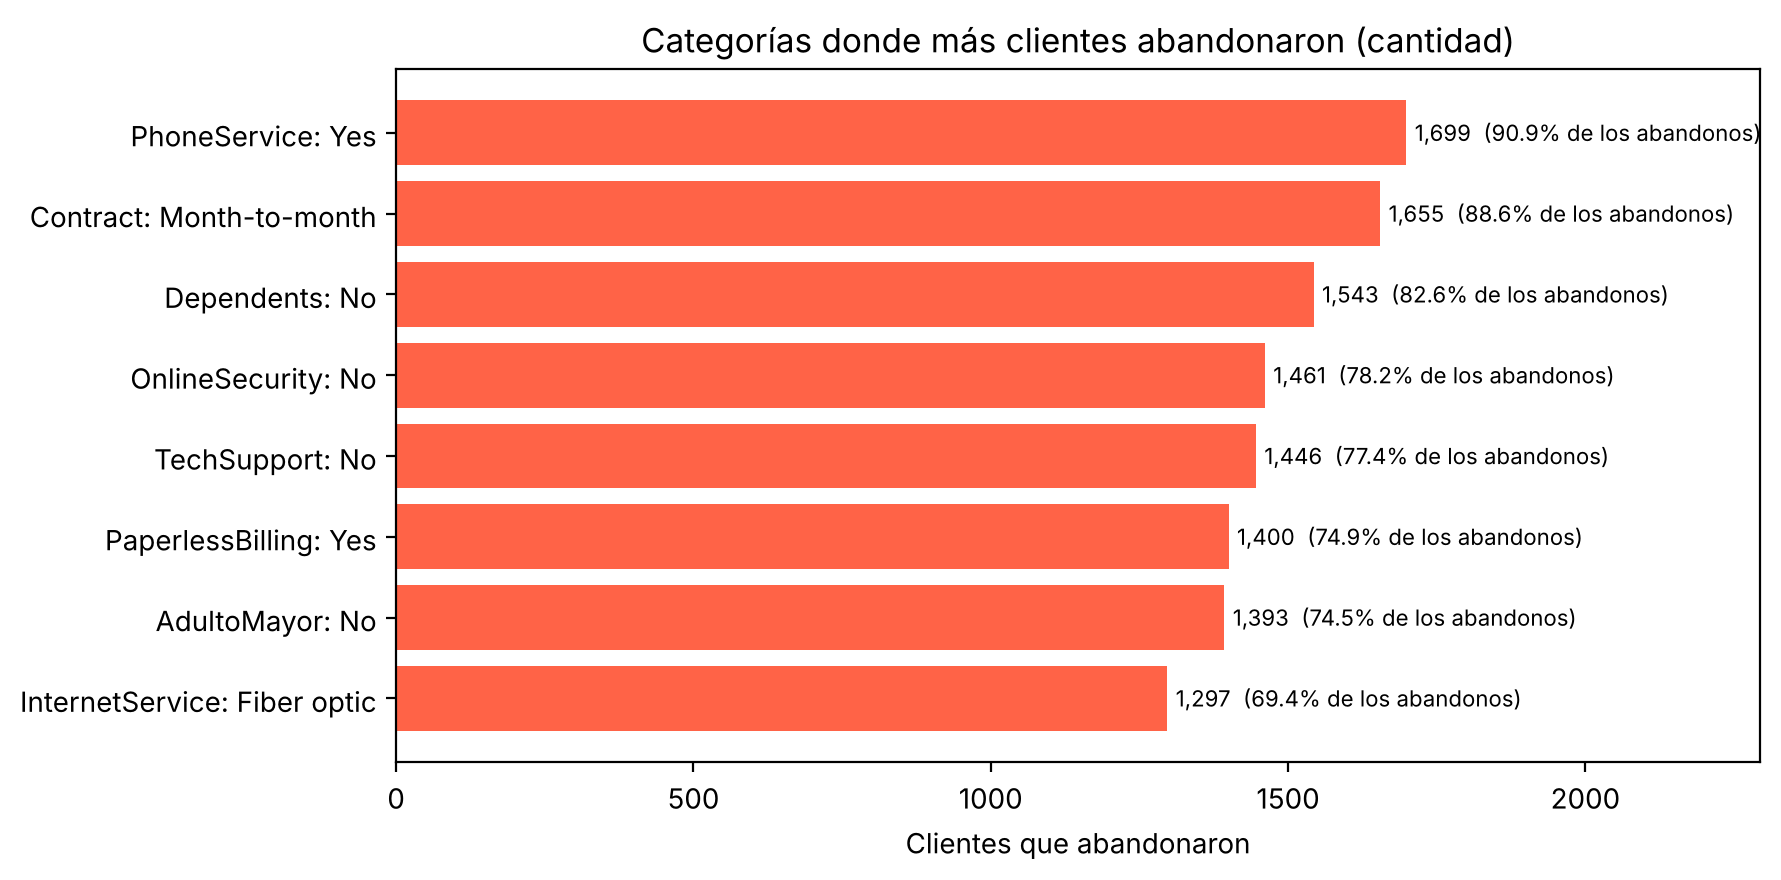

In [38]:

grafico = mas_cantidad.iloc[::-1]
nombres = grafico["Columna"] + ": " + grafico["Categoría"].astype(str)

plt.figure(figsize=(9, 4.5))
barras = plt.barh(nombres, grafico["Abandonaron"], color=COLOR_ABANDONA)
etiquetas = [f"{n:,}  ({p:.1f}% de los abandonos)" for n, p in zip(grafico["Abandonaron"], grafico["% del total de abandonos"])]
plt.bar_label(barras, labels=etiquetas, fontsize=8, padding=3)
plt.xlim(0, grafico["Abandonaron"].max() * 1.35)
plt.title("Categorías donde más clientes abandonaron (cantidad)")
plt.xlabel("Clientes que abandonaron")
plt.tight_layout()
plt.show()


**Lo que observamos:**

- Las categorías donde más clientes abandonaron son: tener servicio de teléfono (1,699), el contrato **mes a mes** (1,655), **no tener dependientes** (1,543), **no tener seguridad en línea** (1,461) y **no tener soporte técnico** (1,446).
- Ojo: una categoría puede tener muchos abandonos simplemente porque tiene muchísimos clientes. Tener servicio de teléfono es el mejor ejemplo: tiene 1,699 abandonos, pero su porcentaje (26.7%) es casi igual al promedio general (26.5%), o sea que no es un factor de riesgo.
- Por eso hay que mirar la cantidad **junto con** el porcentaje. Las que tienen **a la vez** muchos abandonos y un porcentaje alto son: contrato **mes a mes** (1,655 y 42.7%), **sin seguridad en línea** (1,461 y 41.8%), **sin soporte técnico** (1,446 y 41.6%) y **fibra óptica** (1,297 y 41.9%).

## 7. Conclusiones del análisis

Profesor, después de explorar los datos, estas son nuestras conclusiones:

### Sobre la calidad de los datos

- El dataset tiene **7,043 clientes y 21 columnas**, sin filas repetidas.
- El único problema que encontramos fue en `TotalCharges`: **11 clientes** tenían el valor en blanco porque eran clientes nuevos (antigüedad 0). Lo corregimos poniéndoles como total su cargo mensual (`MonthlyCharges`), que es lo que corresponde a su primer cobro.
- Las categorías están bien escritas y los números tienen valores razonables.

### Sobre el abandono

- **El 26.5% de los clientes abandonó**: 1,869 de 7,043 (aproximadamente 1 de cada 4).
- De esos 1,869 abandonos, **1,655 (88.6%) tenían contrato mes a mes**, lo que equivale al 23.5% de toda la muestra.

**Lo que más se relaciona con el abandono:**

| Factor | Lo que encontramos |
|---|---|
| **Tipo de contrato** | Mes a mes: 42.7% de abandono (1,655 clientes). Dos años: 2.8% (48 clientes) |
| **Antigüedad** | En el primer año abandona el 47.4% (1,037 clientes, el 55.5% de todos los abandonos). Después de 4 años, solo el 9.5% (213 clientes) |
| **Tipo de internet** | Fibra óptica: 41.9%. DSL: 19.0% |
| **Forma de pago** | Cheque electrónico: 45.3%. Las demás: entre 15% y 19% |
| **Seguridad en línea y soporte técnico** | Sin el servicio: cerca de 42%. Con el servicio: cerca de 15% |
| **Cargo mensual** | Los que se van pagan más al mes (74.44 contra 61.27 en promedio) |
| **Adulto mayor, pareja y dependientes** | Abandonan más los adultos mayores y los clientes sin pareja ni dependientes |

**Lo que casi no se relaciona con el abandono:**

- El género.
- Tener servicio de teléfono o varias líneas.
- Los servicios de TV y películas por internet.

### El perfil del cliente con más riesgo

> Un cliente **nuevo** (menos de un año), con contrato **mes a mes**, internet de **fibra óptica**, que paga con **cheque electrónico**, con una **mensualidad alta** y **sin** servicios de seguridad ni soporte técnico.

### Recomendaciones para las siguientes etapas del proyecto

- **Para la limpieza y el modelado:**
  - Quitar `customerID`, porque es solo un código y no ayuda a predecir.
  - Convertir las columnas de texto a números para que los modelos las puedan usar.
  - Tener en cuenta que `TotalCharges` repite información de `tenure` y `MonthlyCharges`.
  - Como hay menos clientes que abandonan (26.5%) que clientes que se quedan, fijarse en *recall* y *F1* y no solo en el porcentaje de aciertos.
- **Para los dashboards de Power BI:** los gráficos de contrato, antigüedad, tipo de internet y forma de pago son los que mejor explican el abandono.
- **Ideas de retención para el negocio:** ofrecer beneficios para pasar de contrato mes a mes a contrato anual, dar seguimiento especial a los clientes en su primer año, e incluir seguridad en línea o soporte técnico en los planes de fibra óptica.

### Limitaciones

- Los datos son una "foto" de un solo momento, no sabemos **cuándo** ni **por qué** se fue cada cliente.
- Encontramos **relaciones**, pero eso no significa que una cosa cause la otra. Por ejemplo, no podemos afirmar que la fibra óptica *provoque* el abandono; puede haber otras razones (precio, calidad del servicio, competencia) que no están en los datos.
